# Do US equity perpetuals lead or lag US exchange prices?

**FINM 312 · Lead–lag between Hyperliquid HIP-3 perpetuals and US markets** · implementation plan: [`docs/project_plan.md`](docs/project_plan.md)

Markets: `xyz:NVDA` and `xyz:TSLA` perpetuals vs. their Nasdaq-listed stocks (WRDS TAQ), and `xyz:SP500` vs. CME E-mini S&P futures `ESZ6` (Databento).
Sample: NVDA baseline (Sep 22–24), comparison (Nov 3–5) and crisis (Nov 9–13, CEO transition) windows; TSLA / S&P panel of 30 cash sessions (Sep 21–Oct 16 development, Nov 2–13 evaluation), 2026.

This notebook only **presents** results. Every number is produced by the `leadlag` package and read from `data/results/`. To regenerate:

```bash
leadlag lead-lag --studies nvda_baseline nvda_comparison nvda_crisis --instrument NVDA      # (+ --ref-type mid)
leadlag lead-lag --studies panel --instrument TSLA --holdout                               # (+ --ref-type mid)
leadlag lead-lag --studies panel --instrument SP500 --ref ES --holdout                     # (+ --ref-type mid)
leadlag robustness
leadlag overnight --studies nvda_baseline nvda_comparison nvda_crisis --instrument NVDA --paths
leadlag overnight --studies panel --instrument TSLA --paths
leadlag windows --studies panel --instrument TSLA
leadlag windows --studies panel --instrument SP500 --ref ES
leadlag windows --studies nvda_baseline nvda_comparison nvda_crisis --instrument NVDA
```

**Convention used throughout:** $\rho(k) = \mathrm{Corr}(r^{perp}_t,\ r^{ref}_{t+k})$ on a 1-minute grid. **Positive $k$ means the perpetual moves first.**
The headline statistic is the predefined asymmetry $A = \sum_{k=1}^{5}\rho(k) - \sum_{k=1}^{5}\rho(-k)$ (negative ⇒ the reference market tends to move first), with 95% whole-session bootstrap intervals.

In [1]:
import json, warnings, datetime as dt
warnings.filterwarnings("ignore", message="The 'generic' unit")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from leadlag.config import Config
from leadlag import normalize as N, plots as P

P.set_style()
cfg = Config()
R = cfg.data_dir / "results"
pd.set_option("display.width", 180, "display.max_columns", 30, "display.precision", 4)
def csv(*parts): return pd.read_csv(R.joinpath(*parts))
PAIRS = {"TSLA perp vs TSLA": "TSLA_vs_TSLA", "S&P perp vs ES": "SP500_vs_ES", "NVDA perp vs NVDA": "NVDA_vs_NVDA"}
print("results generated:", sorted({json.load(open(p))["run_utc"][:16] for p in R.glob("*/settings.json")})[-1], "UTC")

results generated: 2026-11-16T17:56 UTC


## 1. Data and coverage

| Series | Source | Price used | Notes |
|---|---|---|---|
| Perpetuals | Dwellir Hyperliquid Index, 1-minute candles | **trade** (candle close, usable at bar end) | sparse: minutes without trades have no bar |
| NVDA, TSLA | WRDS Daily TAQ | **trade** bars (main) and NBBO **midpoints** (robustness, windows, forecasts) | sale-condition filtered; auctions kept separately |
| ES (`ESZ6`) | Databento GLBX.MDP3 | 1-minute **trade** bars (main), 1-second top-of-book **midpoints** | fixed expiry, no roll in sample; every request quoted at $0 |
| Official open/close | TAQ Nasdaq `Q` / `M` records | auction price at its own timestamp | never first/last trade or bar OHLC |

Historical Hyperliquid quotes are not available, so the main specification compares **trade-based** 1-minute prices built the same way on both venues; quote midpoints are the robustness check. Price types are never mixed silently.

In [2]:
rows = []
for name, tag in PAIRS.items():
    for rt in ("trade", "mid"):
        d = csv(f"{tag}_{rt}_1min", "describe.csv")
        d = d[d["period"].isin(["panel", "pooled"])].iloc[0]
        rows.append({"pair": name, "reference price": rt, "sessions": int(d.n_sessions), "paired 1-min returns": int(d.paired_returns),
                     "share of grid paired": d.paired_share, "perp vol (bps/min)": d.perp_vol_bps, "ref vol (bps/min)": d.ref_vol_bps,
                     "perp AC(1)": d.perp_ac1, "ref AC(1)": d.ref_ac1, "same-minute corr": d.contemporaneous_corr})
coverage = pd.DataFrame(rows)
coverage.round(3)

,pair,reference price,sessions,paired 1-min returns,share of grid paired,perp vol (bps/min),ref vol (bps/min),perp AC(1),ref AC(1),same-minute corr
0,TSLA perp vs TSLA,trade,30,11446,0.978,10.509,10.525,0.057,0.062,0.963
1,TSLA perp vs TSLA,mid,29,11061,0.945,10.509,10.531,0.057,0.064,0.967
2,S&P perp vs ES,trade,30,11670,0.997,3.156,3.203,0.028,0.021,0.964
3,S&P perp vs ES,mid,30,11670,0.997,3.156,3.195,0.028,0.022,0.964
4,NVDA perp vs NVDA,trade,11,4279,0.997,14.842,14.803,0.045,0.054,0.981
5,NVDA perp vs NVDA,mid,10,3890,0.907,14.842,14.999,0.045,0.053,0.981


**Known gaps.** WRDS has not built the consolidated NBBO table for **2026-11-11** (raw quotes exist), so midpoint-based results have one fewer NVDA/TSLA session than trade-based ones. TSLA single-stock futures are not used (Databento symbol not yet resolved). First-order autocorrelations are small and positive on both venues, so bid–ask bounce is not driving the results.

## 2. Core result: which venue moves first?

### 2.1 Lead–lag correlations

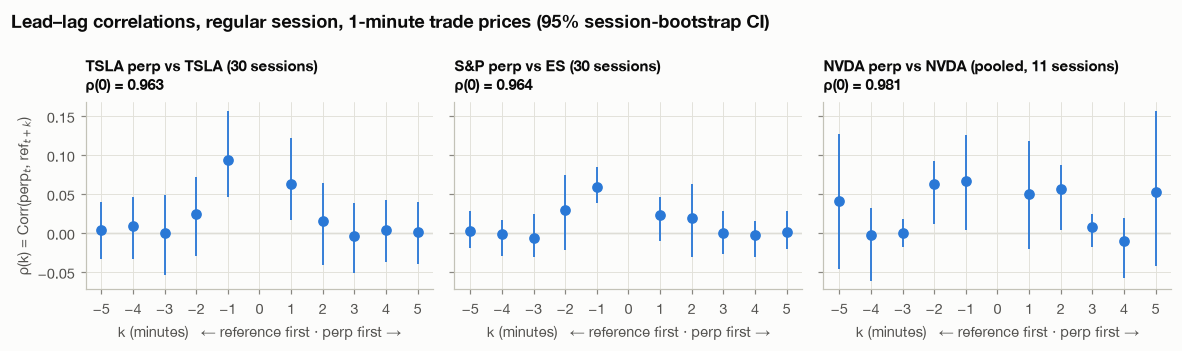

TSLA perp vs TSLA (30 sessions)                       S&P perp vs ES (30 sessions)                       NVDA perp vs NVDA (pooled, 11 sessions)                      
                                rho  ci_lo  ci_hi n_pairs                          rho  ci_lo  ci_hi n_pairs                                     rho  ci_lo  ci_hi n_pairs
lag                                                                                                                                                                       
-5                            0.003 -0.033  0.039   11296                        0.002 -0.020  0.028   11520                                   0.040 -0.047  0.126    4224
-4                            0.008 -0.034  0.045   11326                       -0.002 -0.029  0.016   11550                                  -0.003 -0.062  0.032    4235
-3                            0.000 -0.054  0.049   11356                       -0.006 -0.031  0.025   11580                                   0.000 -0.018  0.017    4246
-2                            0.024 -0.030  0.072   11386                        0.030 -0.022  0.074   11610                                   0.063  0.012  0.093    4257
-1                            0.093  0.046  0.157   11416                        0.059  0.038  0.084   11640                                   0.066  0.004  0.126    4268
 0                            0.963  0.955  0.969   11446                        0.964  0.954  0.970   11670                                   0.981  0.973  0.986    4279
 1                            0.063  0.016  0.121   11417                        0.023 -0.010  0.046   11640                                   0.050 -0.021  0.118    4268
 2                            0.015 -0.042  0.064   11388                        0.019 -0.031  0.063   11610                                   0.057  0.003  0.087    4257
 3                           -0.004 -0.052  0.038   11358                       -0.001 -0.027  0.028   11580                                   0.007 -0.018  0.024    4246
 4                            0.003 -0.038  0.042   11328                       -0.003 -0.031  0.015   11550                                  -0.010 -0.058  0.019    4235
 5                            0.001 -0.041  0.039   11298                        0.001 -0.021  0.028   11520                                   0.053 -0.042  0.157    4224

In [3]:
panels = {}
for name, tag in PAIRS.items():
    x = csv(f"{tag}_trade_1min", "xcorr.csv")
    panels[name + (" (pooled, 11 sessions)" if "NVDA" in name else " (30 sessions)")] = x[x["period"].isin(["panel", "pooled"])]
fig = P.xcorr_panels(panels, "Lead–lag correlations, regular session, 1-minute trade prices (95% session-bootstrap CI)")
plt.show()
pd.concat({k: v.set_index("lag")[["rho", "ci_lo", "ci_hi", "n_pairs"]] for k, v in panels.items()}, axis=1).round(3)

### 2.2 Asymmetry by pair and NVDA window

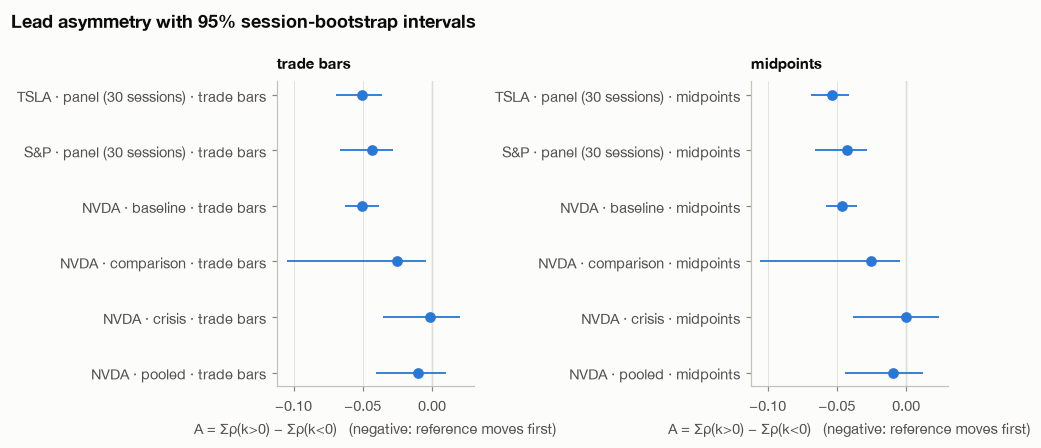

,pair,reference,period,A,ci_lo,ci_hi,sessions,descriptive only
0,TSLA perp vs TSLA,trade bars,panel (30 sessions),-0.0509,-0.0693,-0.0363,30,False
1,TSLA perp vs TSLA,midpoints,panel (30 sessions),-0.0534,-0.0685,-0.0415,29,False
2,S&P perp vs ES,trade bars,panel (30 sessions),-0.0431,-0.0666,-0.0281,30,False
3,S&P perp vs ES,midpoints,panel (30 sessions),-0.0429,-0.0660,-0.0280,30,False
4,NVDA perp vs NVDA,trade bars,baseline,-0.0507,-0.0629,-0.0384,3,True
5,NVDA perp vs NVDA,trade bars,comparison,-0.0253,-0.1049,-0.0044,3,True
6,NVDA perp vs NVDA,trade bars,crisis,-0.0016,-0.0356,0.0205,5,True
7,NVDA perp vs NVDA,trade bars,pooled,-0.0104,-0.0407,0.0099,11,False
8,NVDA perp vs NVDA,midpoints,baseline,-0.0461,-0.0576,-0.0352,3,True
9,NVDA perp vs NVDA,midpoints,comparison,-0.0251,-0.1057,-0.0041,3,True


In [4]:
rows = []
for name, tag in PAIRS.items():
    for rt, lab in (("trade", "trade bars"), ("mid", "midpoints")):
        a = csv(f"{tag}_{rt}_1min", "asymmetry.csv")
        for _, r in a.iterrows():
            per = {"panel": "panel (30 sessions)", "pooled": "pooled"}.get(r["period"], r["period"].replace("nvda_", ""))
            rows.append({"pair": name, "reference": lab, "period": per, "label": f"{name.split(' perp')[0]} · {per} · {lab}",
                         "A": r.A, "ci_lo": r.ci_lo, "ci_hi": r.ci_hi, "sessions": int(r.n_sessions),
                         "descriptive only": bool(r.descriptive_only)})
asym = pd.DataFrame(rows)
fig = P.forest(asym, "label", "A", "ci_lo", "ci_hi", "A = Σρ(k>0) − Σρ(k<0)   (negative: reference moves first)",
               "Lead asymmetry with 95% session-bootstrap intervals", panel="reference")
plt.show()
asym.drop(columns="label").round(4)

NVDA's individual windows have only 3–5 sessions each and are **descriptive only**; their intervals understate uncertainty and are not tests.

### 2.3 Predictive regressions in both directions

$r^{ref}_t$ on its own lags 1..p plus perp lags 1..p (and lagged ES returns for the stocks), and the reverse. The test is a session-clustered F test that the other venue's lags add nothing; $\Delta R^2$ is the incremental fit.

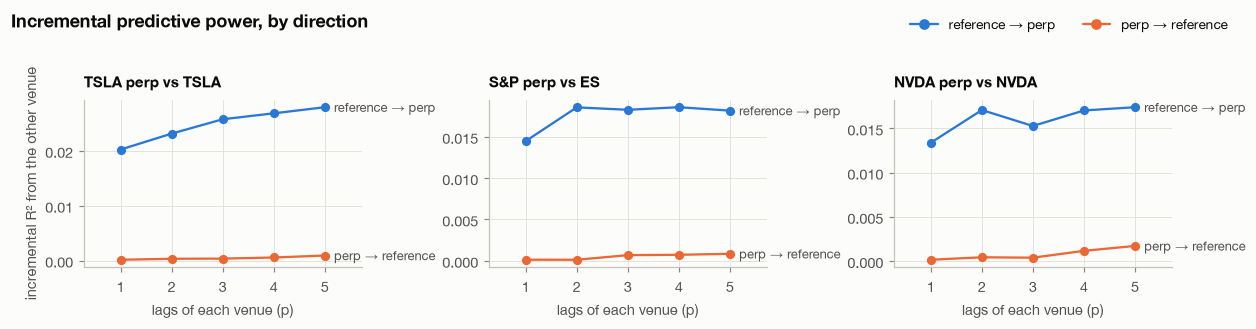

,pair,direction,p,n,n_sessions,controls,delta_r2,p_F,sum_coef,sum_coef_se
0,TSLA perp vs TSLA,perp -> ref,1,11417,30,es_ret,0.0001,0.4334,0.0448,0.0563
1,TSLA perp vs TSLA,ref -> perp,1,11317,30,es_ret,0.0202,0.0000,0.5137,0.0714
2,TSLA perp vs TSLA,perp -> ref,2,11288,30,es_ret,0.0003,0.5562,0.0918,0.0992
3,TSLA perp vs TSLA,ref -> perp,2,11193,30,es_ret,0.0231,0.0000,0.8967,0.1091
4,TSLA perp vs TSLA,perp -> ref,3,11164,30,es_ret,0.0004,0.7421,0.0859,0.1824
5,TSLA perp vs TSLA,ref -> perp,3,11073,30,es_ret,0.0258,0.0000,1.3132,0.1840
6,TSLA perp vs TSLA,perp -> ref,4,11044,30,es_ret,0.0006,0.7437,0.0431,0.2134
7,TSLA perp vs TSLA,ref -> perp,4,10959,30,es_ret,0.0268,0.0000,1.7182,0.2110
8,TSLA perp vs TSLA,perp -> ref,5,10930,30,es_ret,0.0009,0.0342,0.3070,0.2407
9,TSLA perp vs TSLA,ref -> perp,5,10849,30,es_ret,0.0280,0.0000,1.8447,0.2171


In [5]:
reg_tabs, fig_panels = [], {}
for name, tag in PAIRS.items():
    r = csv(f"{tag}_trade_1min", "regressions.csv")
    r = r[r["period"].isin(["panel", "pooled"])]
    t = r.pivot_table(index="p", columns="direction", values="delta_r2").rename(
        columns={"ref -> perp": "reference → perp", "perp -> ref": "perp → reference"})
    fig_panels[name] = t.reset_index()
    tab = r[["direction", "p", "n", "n_sessions", "controls", "delta_r2", "p_F", "sum_coef", "sum_coef_se"]].copy()
    tab.insert(0, "pair", name)
    reg_tabs.append(tab)
fig = P.line_panels(fig_panels, "p", {"reference → perp": "reference → perp", "perp → reference": "perp → reference"},
                    "lags of each venue (p)", "incremental R² from the other venue", "Incremental predictive power, by direction",
                    xticks=range(1, 6))
plt.show()
pd.concat(reg_tabs).round(4)

## 3. Crisis versus baseline (NVDA)

In [6]:
s = csv("NVDA_vs_NVDA_trade_1min", "summary.csv")
s.round(4)

,period,session,sessions,asym_A,asym_ci,peak_lag (exploratory),p(perp->ref) p=5,p(ref->perp) p=5,dR2 perp->ref,dR2 ref->perp,descriptive_only
0,nvda_baseline,regular,3,-0.0507,"[-0.063, -0.038]",0,NaN,NaN,0.0055,0.0270,True
1,nvda_comparison,regular,3,-0.0253,"[-0.105, -0.004]",0,NaN,NaN,0.0035,0.0205,True
2,nvda_crisis,regular,5,-0.0016,"[-0.036, 0.020]",0,NaN,NaN,0.0026,0.0145,True
3,pooled,regular,11,-0.0104,"[-0.041, 0.010]",0,0.506,0.0,0.0017,0.0174,False


### 3.1 The crisis overnight: Nov 11 close → Nov 12 open

Both series are normalized to the **Nov 11 official close** (= 0 bps). Cash includes pre-market and after-hours trades (Form T). The diamonds are the official auction prints, shown as separate events. The public-information timestamp of the CEO-transition news is **not yet verified** (the release is dated Nov 12; the SEC filing reports board action on Nov 11), so no news time is drawn.

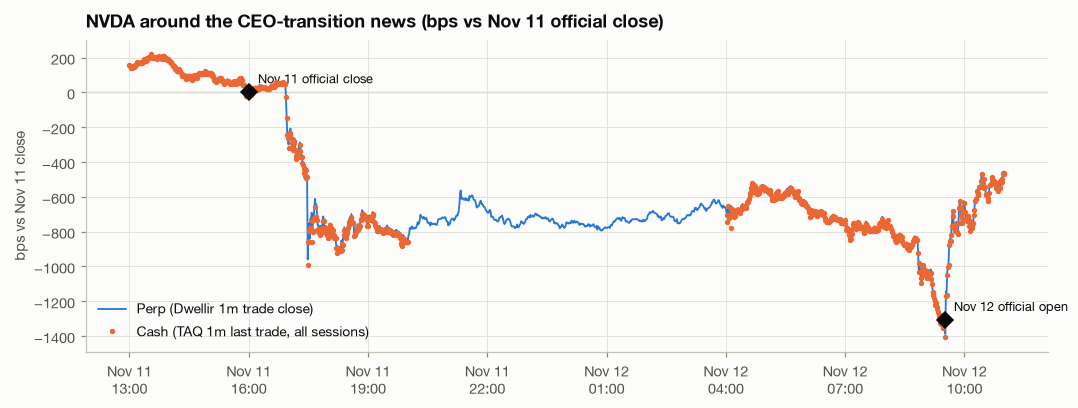

,perp (bps),cash (bps)
2026-11-11 16:00:00-05:00,10.0,7.0
2026-11-11 16:30:00-05:00,28.0,19.0
2026-11-11 17:00:00-05:00,-299.0,-318.0
2026-11-11 20:00:00-05:00,-847.0,-861.0
2026-11-12 04:00:00-05:00,-669.0,NaN
2026-11-12 08:00:00-05:00,-762.0,-774.0
2026-11-12 09:29:00-05:00,-1288.0,-1307.0


In [7]:
days = [dt.date(2026, 11, 11), dt.date(2026, 11, 12)]
auc = csv("overnight_NVDA", "official_prices.csv"); auc["et_date"] = pd.to_datetime(auc.et_date).dt.date
auc = auc.set_index("et_date")
C11 = auc.at[days[0], "close_price"]
perp = N.dwellir_bars(cfg, "xyz:NVDA", cfg.utc_days(days)).set_index("ts_utc")["price"]
cash = N.taq_trade_bars(cfg, "NVDA", days).set_index("ts_utc")["price"]
lo, hi = pd.Timestamp("2026-11-11 13:00", tz="America/New_York"), pd.Timestamp("2026-11-12 11:00", tz="America/New_York")
perp_bps = (perp / C11 - 1).mul(1e4).loc[lo:hi]; cash_bps = (cash / C11 - 1).mul(1e4).loc[lo:hi]
marks = {"Nov 11 official close": (pd.Timestamp(auc.at[days[0], "close_ts_utc"]), 0.0),
         "Nov 12 official open": (pd.Timestamp(auc.at[days[1], "open_ts_utc"]), 1e4 * (auc.at[days[1], "open_price"] / C11 - 1))}
fig = P.event_path(perp_bps, cash_bps, marks, "NVDA around the CEO-transition news (bps vs Nov 11 official close)", "Nov 11 close")
plt.show()
et = lambda s: s.tz_convert("America/New_York")
snap = pd.DataFrame({"perp (bps)": (perp / C11 - 1).mul(1e4), "cash (bps)": (cash / C11 - 1).mul(1e4)})
snap.index = et(snap.index)
checkpoints = ["2026-11-11 16:00", "2026-11-11 16:30", "2026-11-11 17:00", "2026-11-11 20:00", "2026-11-12 04:00", "2026-11-12 08:00", "2026-11-12 09:29"]
snap.reindex(pd.to_datetime(checkpoints).tz_localize("America/New_York"), method="ffill", tolerance=pd.Timedelta("5min")).round(0)

## 4. Robustness

Fixed in advance (none chosen by its result): midpoints vs. trade bars; quote-age limits of 10/30/60 s; excluding the first and last 15 regular minutes; a 5-minute grid. Regressions here use p = 3.

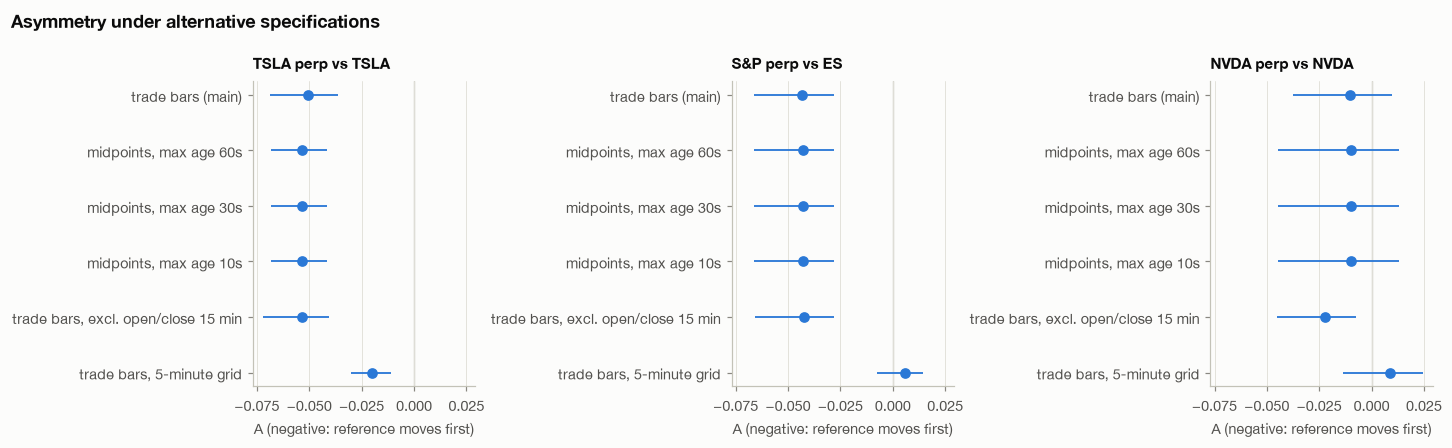

,pair,variant,sessions,paired_returns,asym_A,A_ci_lo,A_ci_hi,p_ref_to_perp,dR2_ref_to_perp,p_perp_to_ref,dR2_perp_to_ref
0,TSLA perp vs TSLA,trade bars (main),30,11446,-0.0509,-0.0689,-0.0364,0.0000,0.0258,0.7421,0.0004
1,TSLA perp vs TSLA,"midpoints, max age 60s",29,11061,-0.0534,-0.0685,-0.0418,0.0000,0.0325,0.6487,0.0004
2,TSLA perp vs TSLA,"midpoints, max age 30s",29,11061,-0.0534,-0.0685,-0.0418,0.0000,0.0325,0.6487,0.0004
3,TSLA perp vs TSLA,"midpoints, max age 10s",29,11053,-0.0533,-0.0684,-0.0418,0.0000,0.0325,0.6494,0.0004
4,TSLA perp vs TSLA,"trade bars, excl. open/close 15 min",30,10582,-0.0537,-0.0722,-0.0404,0.0000,0.0282,0.7189,0.0003
5,TSLA perp vs TSLA,"trade bars, 5-minute grid",30,2280,-0.0202,-0.0302,-0.0108,0.0002,0.0168,0.0155,0.0110
6,S&P perp vs ES,trade bars (main),30,11670,-0.0431,-0.0665,-0.0279,0.0000,0.0183,0.2994,0.0007
7,S&P perp vs ES,"midpoints, max age 60s",30,11670,-0.0429,-0.0661,-0.0279,0.0000,0.0194,0.5054,0.0004
8,S&P perp vs ES,"midpoints, max age 30s",30,11670,-0.0429,-0.0661,-0.0279,0.0000,0.0194,0.5054,0.0004
9,S&P perp vs ES,"midpoints, max age 10s",30,11670,-0.0429,-0.0661,-0.0279,0.0000,0.0194,0.5054,0.0004


In [8]:
rb = csv("robustness.csv")
rb["pair_short"] = rb["pair"].str.replace(" (pooled)", "", regex=False)
fig = P.forest(rb, "variant", "asym_A", "A_ci_lo", "A_ci_hi", "A (negative: reference moves first)",
               "Asymmetry under alternative specifications", panel="pair_short")
plt.show()
rb.drop(columns=["pair_short", "control", "freq"]).round(4)

### 4.1 Chronological holdout (fit Sep–Oct, forecast Nov)

Out-of-sample $R^2$ of the model with the other venue's lags relative to the own-lag baseline, on identical November minutes; the interval is a session bootstrap of the mean loss difference (bps²).

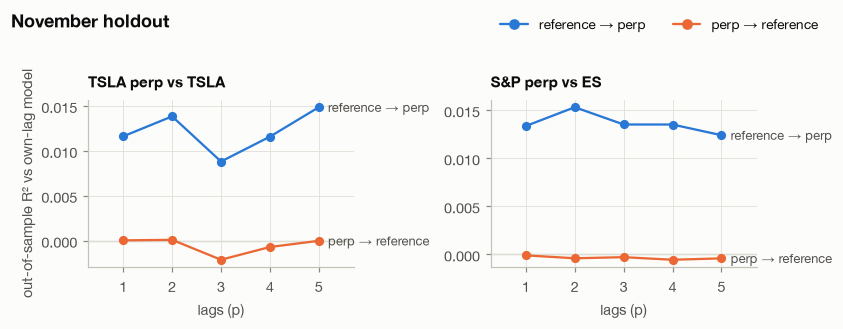

,pair,direction,p,n_eval,eval_sessions,oos_r2_vs_base,mean_loss_diff_bps2,loss_diff_ci_lo_bps2,loss_diff_ci_hi_bps2
0,TSLA perp vs TSLA,perp -> ref,1,3870,10,0.0000,0.0072,-0.0077,0.0235
1,TSLA perp vs TSLA,ref -> perp,1,3865,10,0.0116,1.9436,-0.6387,4.4707
2,TSLA perp vs TSLA,perp -> ref,2,3855,10,0.0001,0.0165,-0.0528,0.0886
3,TSLA perp vs TSLA,ref -> perp,2,3850,10,0.0139,2.2352,-0.4243,4.4158
4,TSLA perp vs TSLA,perp -> ref,3,3840,10,-0.0021,-0.3503,-0.6930,-0.0029
5,TSLA perp vs TSLA,ref -> perp,3,3835,10,0.0088,1.4189,-0.9181,3.4416
6,TSLA perp vs TSLA,perp -> ref,4,3825,10,-0.0007,-0.1141,-0.4586,0.2489
7,TSLA perp vs TSLA,ref -> perp,4,3820,10,0.0116,1.8420,-0.5300,3.8611
8,TSLA perp vs TSLA,perp -> ref,5,3810,10,-0.0000,-0.0014,-0.3097,0.3322
9,TSLA perp vs TSLA,ref -> perp,5,3805,10,0.0149,2.3317,0.4755,4.0458


In [9]:
hp = {}
htabs = []
for name, tag in (("TSLA perp vs TSLA", "TSLA_vs_TSLA"), ("S&P perp vs ES", "SP500_vs_ES")):
    h = csv(f"{tag}_trade_1min", "holdout.csv")
    hp[name] = h.pivot_table(index="p", columns="direction", values="oos_r2_vs_base").rename(
        columns={"ref -> perp": "reference → perp", "perp -> ref": "perp → reference"}).reset_index()
    t = h[["direction", "p", "n_eval", "eval_sessions", "oos_r2_vs_base", "mean_loss_diff_bps2", "loss_diff_ci_lo_bps2", "loss_diff_ci_hi_bps2"]].copy()
    t.insert(0, "pair", name); htabs.append(t)
fig = P.line_panels(hp, "p", {"reference → perp": "reference → perp", "perp → reference": "perp → reference"},
                    "lags (p)", "out-of-sample R² vs own-lag model", "November holdout", xticks=range(1, 6), zero=True)
plt.show()
pd.concat(htabs).round(4)

## 5. Supporting extension: overnight and closing-auction forecasts

Opening forecast $\widehat{O}(t) = C \cdot P(t)/P_0$ from the previous official close $C$ and the perpetual move since that close, at 08:00, 09:00, 09:25 and 09:29 ET; benchmarks are the previous close (no change) and the latest TAQ pre-market midpoint at the same cutoff. Errors are in bps of the official open, scored only on dates where every forecast exists. Perp prices are trade-based.

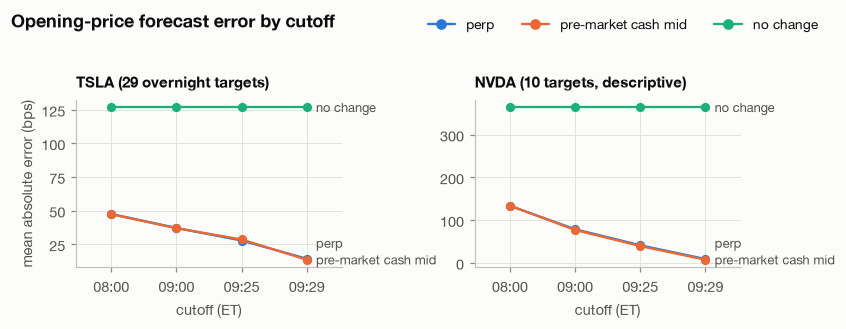

,stock,cutoff,forecast,n_matched,n_missing_or_stale,MAE_bps,RMSE_bps,bias_bps,direction_accuracy,mean_abs_err_diff_perp_minus_this_bps,share_perp_better
0,TSLA,08:00,perp,29,0,47.43,58.83,3.21,0.93,NaN,NaN
1,TSLA,08:00,no_change,29,0,126.62,159.37,14.74,NaN,-79.19,0.90
2,TSLA,08:00,premarket_mid,29,1,47.27,58.74,2.07,0.93,0.15,0.59
3,TSLA,09:00,perp,29,0,37.06,53.19,7.15,0.97,NaN,NaN
4,TSLA,09:00,no_change,29,0,126.62,159.37,14.74,NaN,-89.56,0.97
5,TSLA,09:00,premarket_mid,29,1,36.84,53.04,6.17,0.93,0.22,0.52
6,TSLA,09:25,perp,29,0,27.69,43.47,11.87,0.93,NaN,NaN
7,TSLA,09:25,no_change,29,0,126.62,159.37,14.74,NaN,-98.93,0.93
8,TSLA,09:25,premarket_mid,29,1,28.52,44.16,10.95,0.93,-0.83,0.52
9,TSLA,09:29,perp,29,0,14.18,18.44,6.95,1.00,NaN,NaN


In [10]:
mpanels, mtabs = {}, []
for inst, label in (("TSLA", "TSLA (29 overnight targets)"), ("NVDA", "NVDA (10 targets, descriptive)")):
    m = csv(f"overnight_{inst}", "open_metrics.csv")
    t = m.pivot_table(index="cutoff", columns="forecast", values="MAE_bps").reset_index()
    t["x"] = range(len(t))
    mpanels[label] = t
    m.insert(0, "stock", inst); mtabs.append(m)
fig = P.line_panels(mpanels, "x", {"perp": "perp", "pre-market cash mid": "premarket_mid", "no change": "no_change"},
                    "cutoff (ET)", "mean absolute error (bps)", "Opening-price forecast error by cutoff", xticks=range(4))
for ax in fig.axes[:2]:
    ax.set_xticks(range(4), ["08:00", "09:00", "09:25", "09:29"])
plt.show()
pd.concat(mtabs)[["stock", "cutoff", "forecast", "n_matched", "n_missing_or_stale", "MAE_bps", "RMSE_bps", "bias_bps",
                  "direction_accuracy", "mean_abs_err_diff_perp_minus_this_bps", "share_perp_better"]].round(2)

### 5.1 Daily forecast paths (NVDA)

Error of the perp-implied open (blue) and of the pre-market cash midpoint (orange), in bps of the eventual official open, from the previous close to 09:29 ET.

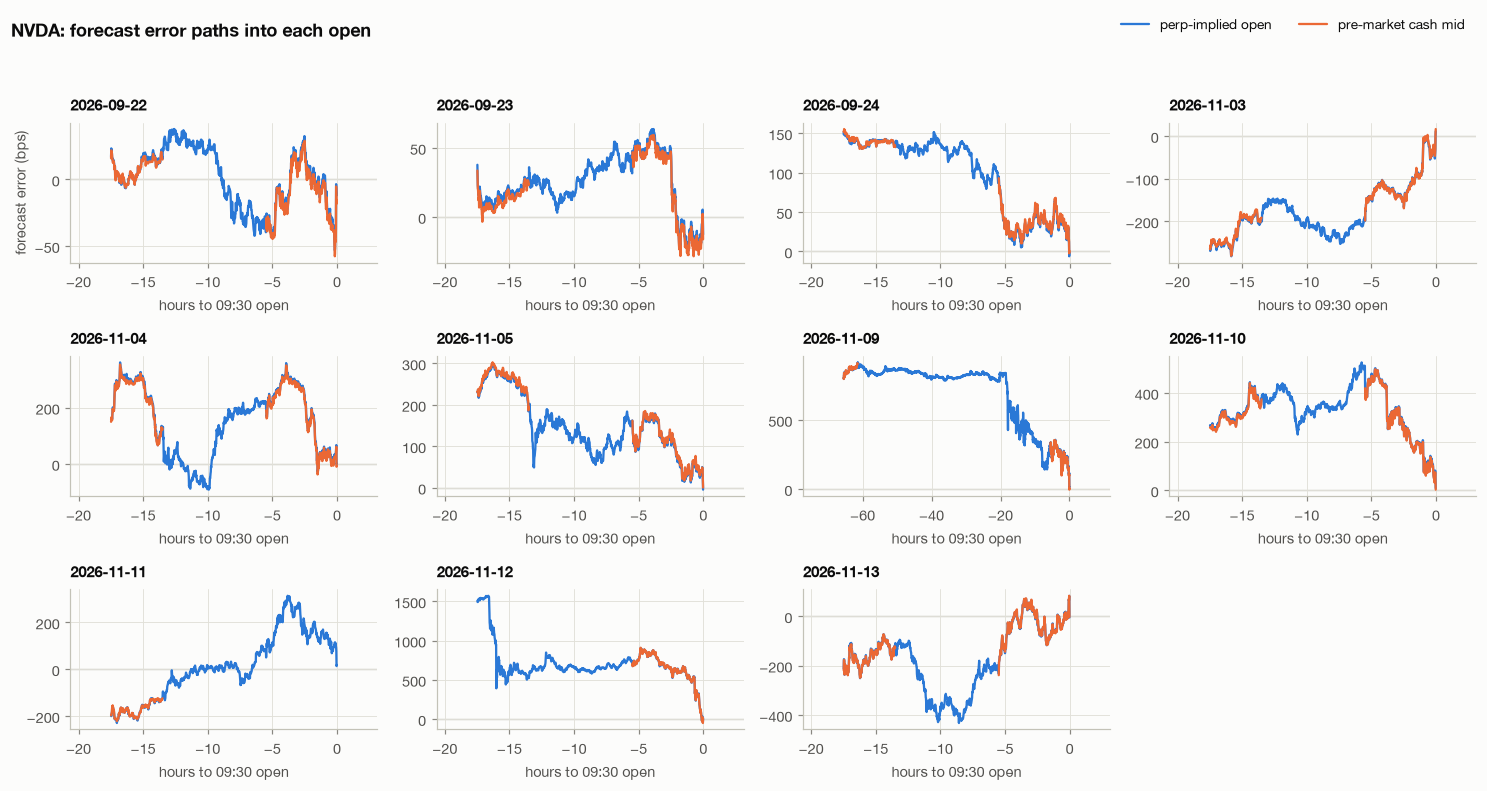

err_bps_perp       err_bps_mid       
                  first  last       first   last
et_date                                         
2026-09-22         17.2 -11.9        15.9  -15.9
2026-09-23         37.7 -12.7        33.6  -16.2
2026-09-24        151.7  -1.3       152.4    0.7
2026-11-03       -263.8  11.0      -265.0   16.1
2026-11-04        158.2   0.5       149.6   -7.9
2026-11-05        230.6  -4.9       231.4    0.3
2026-11-09        803.5  15.8       802.9    4.0
2026-11-10        266.1   8.6       258.0    2.6
2026-11-11       -196.4  18.2      -195.5 -124.5
2026-11-12       1507.9  13.4       697.0   -1.7
2026-11-13       -212.9  -5.4      -219.7   -3.2

In [11]:
pa = csv("overnight_NVDA", "open_paths.csv", )
pa["ts_utc"] = pd.to_datetime(pa["ts_utc"], utc=True)
pa["et_date"] = pd.to_datetime(pa["et_date"]).dt.date
pa["open_utc"] = [pd.Timestamp(dt.datetime.combine(d, dt.time(9, 30)), tz="America/New_York").tz_convert("UTC") for d in pa["et_date"]]
pa["hours_to_open"] = (pa["ts_utc"] - pa["open_utc"]).dt.total_seconds() / 3600
panels = {str(d): g for d, g in pa.groupby("et_date")}
fig = P.line_panels(panels, "hours_to_open", {"perp-implied open": "err_bps_perp", "pre-market cash mid": "err_bps_mid"},
                    "hours to 09:30 open", "forecast error (bps)", "NVDA: forecast error paths into each open",
                    markers=False, zero=True, ncols=4, figsize_per=(3.4, 2.4))
plt.show()
pa.groupby("et_date")[["err_bps_perp", "err_bps_mid"]].agg(["first", "last"]).round(1)

### 5.2 Closing-auction forecasts and the first minutes after the open

Closing forecasts are anchored at 15:00 ET ($\widehat{C}(t) = A_{cash} \cdot P(t)/A_{perp}$) and compared with the contemporaneous cash midpoint at each cutoff.

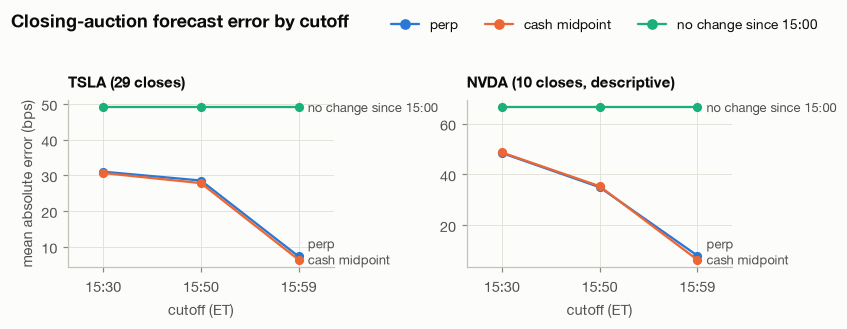

,stock,cutoff,forecast,n_matched,MAE_bps,RMSE_bps,bias_bps,direction_accuracy
0,TSLA,15:30,perp,29,30.99,39.81,1.12,0.79
1,TSLA,15:30,cash_mid,29,30.62,39.80,0.19,0.76
2,TSLA,15:30,anchor_no_change,29,49.01,61.68,2.23,NaN
3,TSLA,15:50,perp,29,28.52,37.45,4.81,0.76
4,TSLA,15:50,cash_mid,29,27.79,36.69,4.56,0.79
5,TSLA,15:50,anchor_no_change,29,49.01,61.68,2.23,NaN
6,TSLA,15:59,perp,29,7.24,9.14,2.00,1.00
7,TSLA,15:59,cash_mid,29,6.32,7.77,1.74,1.00
8,TSLA,15:59,anchor_no_change,29,49.01,61.68,2.23,NaN
0,NVDA,15:30,perp,10,48.42,62.49,-1.69,0.60


,TSLA,NVDA
median after the official open (bps),,
cash_ret_1m_bps,4.21,-44.64
perp_ret_1m_bps,-2.12,-41.82
basis_change_1m_bps,0.77,0.29
cash_ret_5m_bps,-20.87,6.32
perp_ret_5m_bps,-26.11,14.42
basis_change_5m_bps,0.53,-0.77
cash_ret_15m_bps,7.73,40.27
perp_ret_15m_bps,4.27,32.20
basis_change_15m_bps,-0.03,0.09


In [12]:
cpanels, ctabs = {}, []
for inst, label in (("TSLA", "TSLA (29 closes)"), ("NVDA", "NVDA (10 closes, descriptive)")):
    m = csv(f"overnight_{inst}", "close_metrics.csv")
    t = m.pivot_table(index="cutoff", columns="forecast", values="MAE_bps").reset_index(); t["x"] = range(len(t))
    cpanels[label] = t; m.insert(0, "stock", inst); ctabs.append(m)
fig = P.line_panels(cpanels, "x", {"perp": "perp", "cash midpoint": "cash_mid", "no change since 15:00": "anchor_no_change"},
                    "cutoff (ET)", "mean absolute error (bps)", "Closing-auction forecast error by cutoff", xticks=range(3))
for ax in fig.axes[:2]:
    ax.set_xticks(range(3), ["15:30", "15:50", "15:59"])
plt.show()
adj = pd.concat({inst: csv(f"overnight_{inst}", "post_open_adjustment.csv").filter(regex="(cash_ret|perp_ret|basis_change)_").median()
                 for inst in ("TSLA", "NVDA")}, axis=1)
display(pd.concat(ctabs)[["stock", "cutoff", "forecast", "n_matched", "MAE_bps", "RMSE_bps", "bias_bps", "direction_accuracy"]].round(2))
adj.round(2).rename_axis("median after the official open (bps)")

## 6. Supporting extension: opening and closing windows

Windows run from 30 minutes before to 30 minutes after each boundary (09:30 open, 16:00 close). For the stocks the boundary is the Nasdaq auction; for the S&P perp vs. ES it is a cash-session boundary (16:00 ET is also CME's settlement time, a different event). Pre and post sides are separate sessions, so no return or lag crosses the auction. The reference here is the quote midpoint.

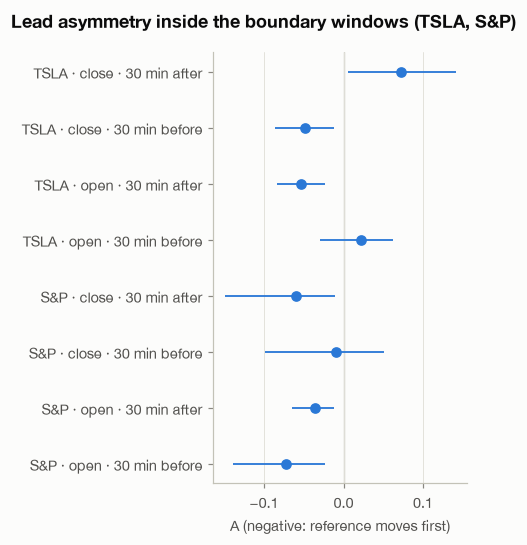

,pair,window,side,n_sessions,paired_returns,sufficiently_populated,contemporaneous_corr,A,ci_lo,ci_hi
0,TSLA perp vs TSLA,close,30 min after,29,775,True,0.881,0.072,0.005,0.141
1,TSLA perp vs TSLA,close,30 min before,29,883,True,0.959,-0.048,-0.086,-0.012
2,TSLA perp vs TSLA,open,30 min after,29,839,True,0.984,-0.053,-0.084,-0.023
3,TSLA perp vs TSLA,open,30 min before,29,888,True,0.953,0.022,-0.030,0.062
0,S&P perp vs ES,close,30 min after,30,868,True,0.941,-0.059,-0.149,-0.011
1,S&P perp vs ES,close,30 min before,30,930,True,0.962,-0.010,-0.098,0.051
2,S&P perp vs ES,open,30 min after,30,870,True,0.963,-0.036,-0.065,-0.012
3,S&P perp vs ES,open,30 min before,30,930,True,0.932,-0.072,-0.139,-0.023
0,NVDA perp vs NVDA,close,30 min after,10,290,False,0.973,-0.068,-0.145,-0.030
1,NVDA perp vs NVDA,close,30 min before,10,310,True,0.967,0.017,-0.050,0.077


In [13]:
WIN = {"TSLA perp vs TSLA": "windows_TSLA_vs_TSLA_mid", "S&P perp vs ES": "windows_SP500_vs_ES_mid", "NVDA perp vs NVDA": "windows_NVDA_vs_NVDA_mid"}
wrows = []
for name, tag in WIN.items():
    d = csv(tag, "describe.csv"); a = csv(tag, "asymmetry.csv")
    m = d.merge(a[["window", "side", "A", "ci_lo", "ci_hi"]], on=["window", "side"])
    m.insert(0, "pair", name); wrows.append(m)
wl = pd.concat(wrows)
wl["side"] = wl["side"].map({"pre": "30 min before", "post": "30 min after"})
wl["label"] = wl["pair"].str.split(" perp").str[0] + " · " + wl["window"] + " · " + wl["side"]
fig = P.forest(wl[wl.pair != "NVDA perp vs NVDA"], "label", "A", "ci_lo", "ci_hi", "A (negative: reference moves first)",
               "Lead asymmetry inside the boundary windows (TSLA, S&P)")
plt.show()
wl[["pair", "window", "side", "n_sessions", "paired_returns", "sufficiently_populated", "contemporaneous_corr", "A", "ci_lo", "ci_hi"]].round(3)

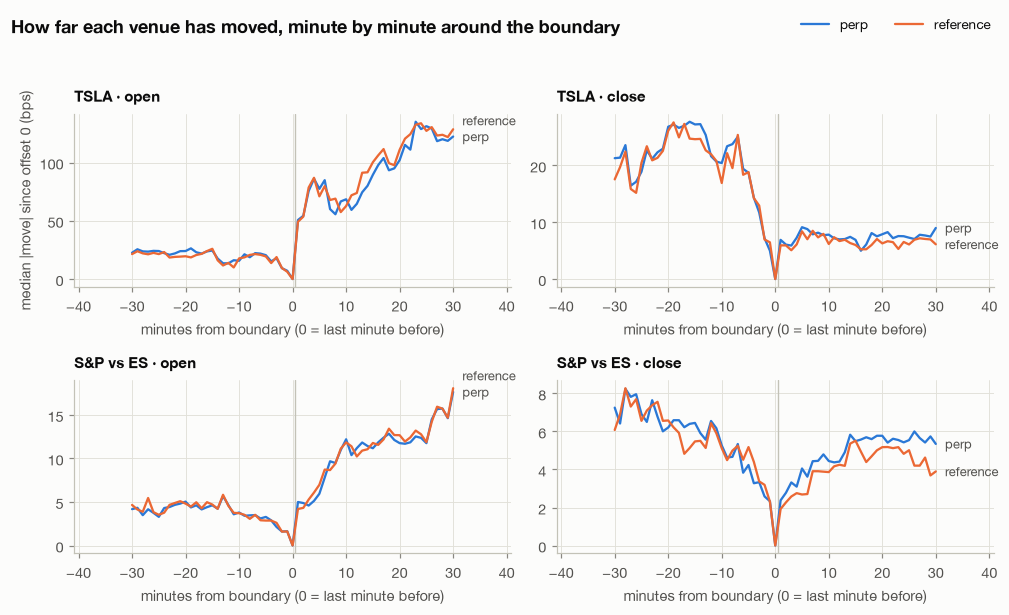

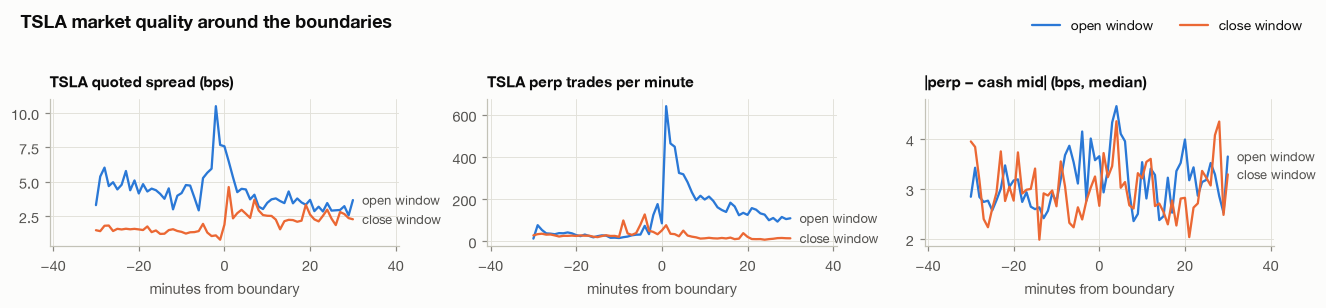

basis_pre_bps  auction_price  auction_vs_pre_ref_bps  perp_ret_1m_bps  ref_ret_1m_bps  basis_change_1m_bps  perp_ret_5m_bps  ref_ret_5m_bps  \
                  window                                                                                                                                                
TSLA perp vs TSLA close            2.24         377.88                    0.00            -0.53           -2.22                 1.79            -2.36           -2.61   
                  open             0.78         373.58                   -4.77            -2.92           -7.57                -0.40           -23.59          -37.13   
S&P perp vs ES    close          -66.90            NaN                     NaN             1.10            0.97                 0.37             1.64            1.65   
                  open           -66.41            NaN                     NaN            -0.77           -0.65                -0.14             1.23            1.77   
NVDA perp vs NVDA close            3.62         181.60                    2.65             2.30            1.61                 0.87            -2.30           -4.04   
                  open             2.67         196.00                    1.76           -33.26          -44.23                 0.32            26.31            6.56   

                          basis_change_5m_bps  perp_ret_15m_bps  ref_ret_15m_bps  basis_change_15m_bps  
                  window                                                                                
TSLA perp vs TSLA close                  0.00             -3.67            -3.91                  0.00  
                  open                   1.21              1.03            -7.78                  0.02  
S&P perp vs ES    close                  0.53              2.69             1.43                  0.48  
                  open                   0.11              4.43             5.56                 -0.34  
NVDA perp vs NVDA close                 -1.57             -3.99            -1.32                  0.47  
                  open                   6.15             30.25            41.18                 -0.44

In [14]:
prof = {}
for name, tag in (("TSLA", "windows_TSLA_vs_TSLA_mid"), ("S&P vs ES", "windows_SP500_vs_ES_mid")):
    p = csv(tag, "event_profile.csv")
    for w in ("open", "close"):
        prof[f"{name} · {w}"] = p[p.window == w]
fig = P.line_panels(prof, "offset_min", {"perp": "abs_perp_path_med_bps", "reference": "abs_ref_path_med_bps"},
                    "minutes from boundary (0 = last minute before)", "median |move| since offset 0 (bps)",
                    "How far each venue has moved, minute by minute around the boundary", markers=False, ncols=2,
                    figsize_per=(4.6, 2.8))
for ax in fig.axes[:4]:
    ax.axvline(0.5, color=P.AXIS, lw=0.9)
plt.show()
q = {}
for w in ("open", "close"):
    p = csv("windows_TSLA_vs_TSLA_mid", "event_profile.csv"); q[w] = p[p.window == w]
fig = P.line_panels({"TSLA quoted spread (bps)": pd.DataFrame({"offset_min": q["open"].offset_min.values, "open": q["open"].ref_spread_med_bps.values, "close": q["close"].ref_spread_med_bps.values}),
                     "TSLA perp trades per minute": pd.DataFrame({"offset_min": q["open"].offset_min.values, "open": q["open"].perp_trades_mean.values, "close": q["close"].perp_trades_mean.values}),
                     "|perp − cash mid| (bps, median)": pd.DataFrame({"offset_min": q["open"].offset_min.values, "open": q["open"].abs_basis_med_bps.values, "close": q["close"].abs_basis_med_bps.values})},
                    "offset_min", {"open window": "open", "close window": "close"}, "minutes from boundary", "", "TSLA market quality around the boundaries",
                    markers=False, figsize_per=(4.0, 2.8))
plt.show()
ch = pd.concat({n: csv(t, "event_changes.csv").groupby("window").median(numeric_only=True) for n, t in WIN.items()})
ch.round(2)

## 7. Limitations

- **Trade-based perp prices.** Historical Hyperliquid quotes are unavailable, so the perp side uses 1-minute candle closes. A bar's close is usable at its end, but the time of its last trade is unknown, so no sub-minute timing claim is possible. Midpoint robustness changes the reference side only.
- **Sample size.** 30 cash sessions for TSLA and the S&P; 3–5 per NVDA window (descriptive only). Overnight-forecast samples are 29 (TSLA) and 10 (NVDA) targets; a handful of overnight outcomes cannot establish forecasting skill.
- **Regime.** The November evaluation block includes the NVDA crisis and differs from September–October.
- **Predictive, not causal.** Lead–lag at a 1-minute grid says which series' past returns help predict the other's; it does not establish causality or which venue reacts first within a minute.
- **Event chronology.** The NVDA news timestamp is unverified; the perp and cash after-hours moves on Nov 11 make that verification essential before any event-time claim.
- **Data gaps.** No WRDS NBBO for 2026-11-11; TSLA single-stock futures unresolved; the ES level difference includes carry and is not a pricing error.
- **Multiple comparisons.** The windows study runs eight window tests and the robustness grid eighteen; isolated significant cells (such as TSLA's after-close window) are exploratory.

## 8. Conclusion

**Which venue leads, at what horizon?** During regular trading, the US reference markets move slightly **before** the perpetuals at the one-minute horizon, not the other way round.

- **TSLA:** asymmetry $A = -0.051$ (95% CI −0.069 to −0.036, 30 sessions). Past stock returns add about **2.8%** incremental $R^2$ for the perp; past perp returns add **0.09%** for the stock.
- **S&P perp vs ES:** $A = -0.043$ (−0.067 to −0.028). ES lags add **1.8%** for the perp; perp lags add **0.08%** for ES.
- **Out of sample (fit Sep–Oct, forecast Nov):** ES returns improve perp forecasts by **1.2–1.5%** $R^2$, with intervals above zero at every lag length. TSLA's gain is similar in size (0.9–1.5%), but its interval excludes zero only at p = 5. Perp returns never improve forecasts of the reference.
- **Robust at one minute:** the result holds with quote midpoints, under every quote-age limit, and with the open and close excluded.
- **The lead is short:** on a 5-minute grid TSLA's asymmetry shrinks to −0.020, and the S&P and NVDA are indistinguishable from zero.
- **Most movement is simultaneous:** same-minute correlations are 0.96–0.98, so most price movement is shared within the minute. The lead is a small residual, measured with trade-based perp prices on a one-minute grid, and does not establish causality or sub-minute reaction order.

**Does it change during major news?** Possibly, but this sample cannot test it.

- **NVDA by window:** the stock leads in the baseline (−0.051) and comparison (−0.025) windows, but the asymmetry is essentially zero in the crisis week (−0.002). Pooled, it is −0.010 (−0.038 to 0.010).
- **Too few sessions:** each window has only 3–5 sessions, so this is a descriptive pattern, not a test.
- **The crisis overnight:** on Nov 11 the perp and the stock's after-hours trades fell together (about −9.6% and −9.9% by 17:00 ET). Between 20:00 and 04:00 the perp was the only venue trading, and the stock's 04:00 pre-market price was close to where the perp had drifted.
- **Next step:** verify the public-information timestamp before attributing that move to the CEO-transition release.

**Overnight and auction forecasts (supporting).**

- **Opening forecasts:** the perp-implied opening price beats the previous close by a wide margin. For TSLA at 09:29 ET, the mean absolute error is 14 bps versus 127 bps for no change, and the perp gets the gap direction right on 93–100% of days.
- **No better than the stock's own pre-market price:** it is about as accurate as the cash pre-market midpoint at every cutoff (within about 1–2 bps either way). Because the stock trades before the open, this is not evidence of independent perp price discovery.
- **Closing forecasts:** the perp-implied close matches the contemporaneous cash midpoint and beats no change from 15:00.

**Opening and closing windows (supporting).**

- **No gap after the auction:** the perp–cash price difference barely changes in the 15 minutes after either auction (median under 1 bp), so the auctions do not leave a gap that one venue then closes.
- **Inside the windows the reference usually leads.** The exception is TSLA's 30 minutes after the close, where the perp leads: $A = +0.072$ (0.005 to 0.141). That is one of eight window tests, in thin after-hours trading, so treat it as exploratory.

**Answer to the research question:** in this sample, US equity perpetuals **lag** their reference markets slightly at the one-minute horizon during regular trading, and that lag disappears at five minutes. Outside regular hours the perp keeps pace with, but does not clearly beat, the stock's own extended-hours prices. The NVDA crisis week shows no lag, but the sample is too small to call that a change.